# SARIMAX — Previsão do Preço Diário do Trigo no RS com Paridade de Importação e Precipitação

**TCC — Sistemas de Informação | PUCRS**
Bruno Origem Noronha

Este notebook implementa o **SARIMAX** em **granularidade diária** para o trigo: o SARIMA do baseline (`sarima_trigo.ipynb`)
acrescido de **variáveis exógenas** (explicativas). O "X" do nome vem de *eXogenous*.

- **Variável alvo (y, endógena):** preço diário do trigo no Rio Grande do Sul, em reais por tonelada (`preco_brl`, Indicador CEPEA/ESALQ - RS)
- **Variáveis exógenas candidatas (X):**
  1. **Câmbio** — cotação de venda do dólar (`dolar_venda`, R\$/US\$, Banco Central);
  2. **Preço internacional** — contrato futuro contínuo do trigo na **Bolsa de Chicago (CBOT, ticker `ZW=F`)**, em **US\$/tonelada** (`cbot_usd_t`);
  3. **Paridade de importação** — índice único `CBOT × dólar` (R\$/t, sem frete e impostos);
  4. **Precipitação** — chuva média diária nas praças de soja e trigo do RS (Cruz Alta, Passo Fundo e Santa Rosa), no dia e acumulada em 7, 15 e 30 dias.

O Brasil importa parte relevante do trigo que consome, então o preço interno tende a acompanhar o custo de trazer o grão de fora:
**preço em Chicago × câmbio**. Mas o mercado gaúcho absorve esses movimentos com **atraso** (*transmission lag*): contratos, logística e
comercialização da safra fazem a informação chegar ao preço regional dias ou semanas depois. Por isso testamos as exógenas **defasadas**.

**Estratégia de seleção (sem olhar o teste):** todos os candidatos usam a mesma ordem do SARIMA de referência, (1,1,1)(1,0,1)[7],
são ajustados **apenas no treino** e comparados pelo **AIC**. As métricas de teste só são usadas para **avaliar** o modelo escolhido.

Roteiro:
1. Carregamento, alinhamento diário, defasagens e divisão cronológica (treino até 31/01/2026 · teste de 01/02 a 02/03/2026)
2. Análise de estacionariedade (teste ADF) e correlação defasada
3. Ajuste dos modelos: SARIMAX básico → defasagens de câmbio/CBOT e paridade → precipitação → modelo final
4. Previsão no período de teste, métricas (RMSE, MAE, MAPE) e comparação com o SARIMA e o SARIMAX básico
5. Visualização gráfica e exportação

In [1]:
# Bibliotecas
import os
import warnings
warnings.filterwarnings("ignore")   # esconde avisos internos das bibliotecas, para a saída ficar limpa

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.tsa.stattools import adfuller           # teste de estacionariedade
from statsmodels.tsa.statespace.sarimax import SARIMAX   # modelo SARIMAX

pd.set_option("display.max_colwidth", None)   # mostra os coeficientes completos nas tabelas de AIC
pd.set_option("display.width", 250)

# Pasta onde salvamos o gráfico e as métricas
PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

## 1. Carregamento e alinhamento diário

### 1.1 Leitura e unificação das bases

- **Preço (y) e precipitação:** vêm do dataset integrado `dataset_final_trigo.csv` (colunas `preco_brl`, `precipitacao_mm` e
  `precipitacao_acc_7/15/30`). A precipitação já é a **média das praças** de soja e trigo, como no SARIMAX do arroz.
- **Câmbio:** `dolar_limpo.csv` (série completa desde 01/01/2008).
- **CBOT:** `cbot_trigo_limpo.csv`, gerado por `src/data/make_cbot_trigo.py` a partir do Yahoo Finance (`ZW=F`), em US\$/t.
- **Valores ausentes:** fins de semana e feriados (no Brasil ou nos EUA) recebem o **último valor conhecido** (`ffill`).

> **Atenção à coluna `preco_usd`:** ela **não** é um preço internacional — é o próprio indicador CEPEA-RS convertido em dólar
> (`preco_usd ≈ preco_brl / dolar_venda`). Usá-la como exógena seria vazar o alvo para dentro do modelo, por isso ela fica de fora.

In [2]:
# Lê as bases
trigo = pd.read_csv("../data/processed/dataset_final_trigo.csv", parse_dates=["data"], index_col="data")
dolar = pd.read_csv("../data/processed/dolar_limpo.csv",        parse_dates=["data"], index_col="data")
cbot  = pd.read_csv("../data/processed/cbot_trigo_limpo.csv",   parse_dates=["data"], index_col="data")

CHUVA = ["precipitacao_mm", "precipitacao_acc_7", "precipitacao_acc_15", "precipitacao_acc_30"]

# Câmbio e CBOT completos (começam um mês antes do dataset do trigo, o que permite defasagens de até 30 dias sem perder linhas)
macro = dolar[["dolar_venda"]].join(cbot["cbot_usd_t"], how="left").asfreq("D").ffill()
macro["paridade"] = macro["cbot_usd_t"] * macro["dolar_venda"]   # custo do trigo de Chicago em R$/t

print("Valores ausentes antes do tratamento:")
print(trigo[["preco_brl"] + CHUVA].asfreq("D").isna().sum().to_string())
print(f"Câmbio/CBOT completos a partir de {macro.dropna().index[0]:%d/%m/%Y}")

Valores ausentes antes do tratamento:
preco_brl              0
precipitacao_mm        0
precipitacao_acc_7     0
precipitacao_acc_15    0
precipitacao_acc_30    0
Câmbio/CBOT completos a partir de 02/01/2008


### 1.2 Defasagens das variáveis de paridade

Para cada defasagem $k \in \{0, 7, 14, 21, 30\}$ dias criamos `dolar_lag_k`, `cbot_lag_k` e `paridade_lag_k`, com o valor observado
$k$ dias antes: `shift(k)`. O preço do dia $t$ passa a ser explicado pelo câmbio e pela CBOT de $t-k$.

**Sem vazamento:** `shift(k)` só traz valores do passado. Um bônus prático: com $k \geq 30$, todas as exógenas do teste
(01/02 a 02/03) já eram conhecidas em 31/01/2026, ou seja, a previsão passa a ser **genuinamente operacional** — não depende de
valores futuros do câmbio ou da CBOT.

In [3]:
LAGS = [0, 7, 14, 21, 30]

for k in LAGS:
    macro[f"dolar_lag_{k}"]    = macro["dolar_venda"].shift(k)
    macro[f"cbot_lag_{k}"]     = macro["cbot_usd_t"].shift(k)
    macro[f"paridade_lag_{k}"] = macro["paridade"].shift(k)

# Une tudo no calendário do preço do trigo
dados = trigo[["preco_brl"] + CHUVA].asfreq("D").join(macro, how="left")
dados[["preco_brl"] + CHUVA] = dados[["preco_brl"] + CHUVA].ffill()

assert dados.isna().sum().sum() == 0, "Ainda há valores ausentes"
print(f"Período total: {dados.index[0]:%d/%m/%Y} a {dados.index[-1]:%d/%m/%Y} ({len(dados)} dias) | sem valores ausentes")

Período total: 01/02/2008 a 20/04/2026 (6654 dias) | sem valores ausentes


### 1.3 Divisão cronológica: treino vs. teste

A divisão é **idêntica à do SARIMA do trigo** (e à do arroz), para que as métricas sejam diretamente comparáveis:

| Conjunto | Período | Justificativa |
|---|---|---|
| **Treino** | início da série até **31/01/2026** | inclui a **pandemia de 2020** e o pico de preços da **guerra Rússia–Ucrânia em 2022** |
| **Teste** | **01/02/2026 a 02/03/2026** (30 dias) | horizonte de **curto prazo**, coerente com o uso prático de uma previsão diária |

In [4]:
FIM_TREINO = "2026-01-31"
HORIZONTE  = 30   # dias de teste a partir de 01/02/2026 (o mesmo do SARIMA)

treino = dados.loc[:FIM_TREINO]
teste  = dados.loc["2026-02-01":].iloc[:HORIZONTE]
y_treino, y_teste = treino["preco_brl"], teste["preco_brl"]

print(f"Treino: {len(y_treino)} dias ({y_treino.index[0]:%d/%m/%Y} a {y_treino.index[-1]:%d/%m/%Y})")
print(f"Teste : {len(y_teste)} dias ({y_teste.index[0]:%d/%m/%Y} a {y_teste.index[-1]:%d/%m/%Y})")

Treino: 6575 dias (01/02/2008 a 31/01/2026)
Teste : 30 dias (01/02/2026 a 02/03/2026)


### 1.4 Visão geral da série de treino

Preço do trigo gaúcho (R\$/t) ao lado da **paridade de importação** (CBOT × dólar, em R\$/t, sem frete e impostos).

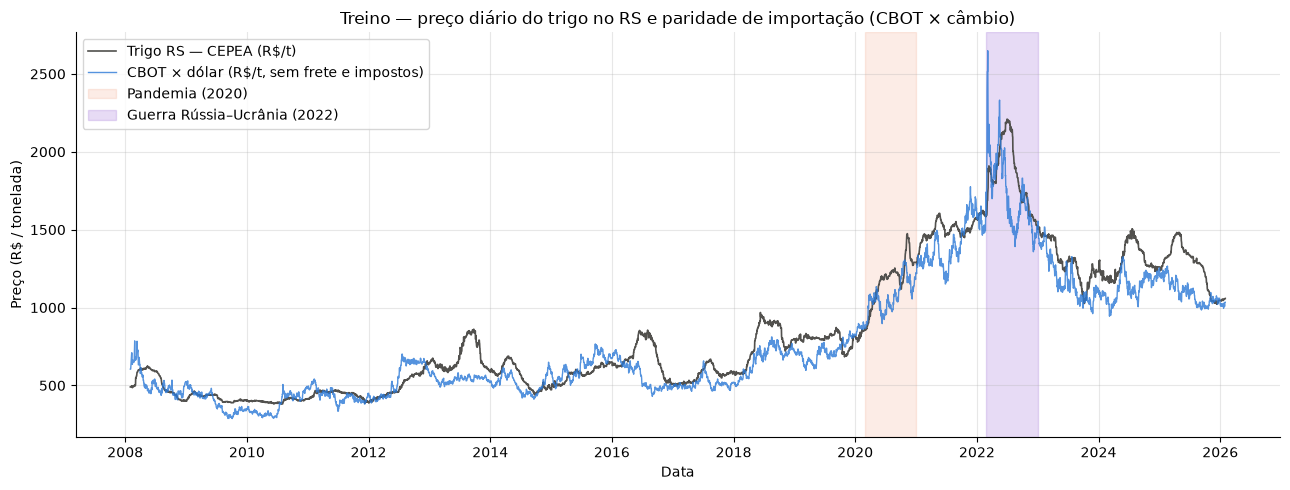

In [5]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(y_treino, color="#52514e", lw=1.2, label="Trigo RS — CEPEA (R$/t)")
ax.plot(treino["paridade"], color="#2a78d6", lw=1.0, alpha=0.8, label="CBOT × dólar (R$/t, sem frete e impostos)")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-31"), color="#eb6834", alpha=0.12, label="Pandemia (2020)")
ax.axvspan(pd.Timestamp("2022-02-24"), pd.Timestamp("2022-12-31"), color="#7a3cc8", alpha=0.18, label="Guerra Rússia–Ucrânia (2022)")

ax.set_title("Treino — preço diário do trigo no RS e paridade de importação (CBOT × câmbio)")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / tonelada)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. Análise de estacionariedade e correlação defasada

### 2.1 Teste ADF

- **Hipótese nula (H₀):** a série tem raiz unitária, ou seja, **não é estacionária**.
- **Regra de decisão:** p-valor **< 0,05** → rejeitamos H₀ → a série é estacionária.

In [6]:
def teste_adf(s, nome):
    estatistica, p_valor = adfuller(s)[:2]   # 1º item: estatística; 2º item: p-valor
    conclusao = "estacionária" if p_valor < 0.05 else "NÃO estacionária"
    print(f"{nome:<32} ADF = {estatistica:8.3f}   p-valor = {p_valor:.4f}  ->  {conclusao}")

teste_adf(y_treino,                              "Trigo — original")
teste_adf(y_treino.diff().dropna(),              "Trigo — 1ª diferença")
teste_adf(treino["dolar_venda"],                 "Dólar — original")
teste_adf(treino["dolar_venda"].diff().dropna(), "Dólar — 1ª diferença")
teste_adf(treino["cbot_usd_t"],                  "CBOT — original")
teste_adf(treino["paridade"],                    "Paridade — original")
teste_adf(treino["paridade"].diff().dropna(),    "Paridade — 1ª diferença")
teste_adf(treino["precipitacao_mm"],             "Precipitação — original")
teste_adf(treino["precipitacao_acc_30"],         "Precipitação acum. 30d — original")

Trigo — original                 ADF =   -1.421   p-valor = 0.5721  ->  NÃO estacionária
Trigo — 1ª diferença             ADF =  -13.437   p-valor = 0.0000  ->  estacionária


Dólar — original                 ADF =   -0.822   p-valor = 0.8125  ->  NÃO estacionária
Dólar — 1ª diferença             ADF =  -14.773   p-valor = 0.0000  ->  estacionária


CBOT — original                  ADF =   -4.618   p-valor = 0.0001  ->  estacionária


Paridade — original              ADF =   -1.302   p-valor = 0.6281  ->  NÃO estacionária
Paridade — 1ª diferença          ADF =  -15.522   p-valor = 0.0000  ->  estacionária


Precipitação — original          ADF =  -12.721   p-valor = 0.0000  ->  estacionária
Precipitação acum. 30d — original ADF =   -6.784   p-valor = 0.0000  ->  estacionária


**Leitura:**

- O **preço do trigo**, o **dólar** e a **paridade** não são estacionários no nível, mas são na primeira diferença: adotamos **d = 1**, como no SARIMA.
- A **CBOT** e a **precipitação** (no dia ou acumulada) já são estacionárias no nível: oscilam em torno de uma média de longo prazo.
- Com **d = 1**, o SARIMAX diferencia o modelo inteiro (alvo e exógenas). Os coeficientes medem, portanto, o efeito da **variação diária**
  de cada exógena sobre a **variação diária** do preço do trigo, o que evita a **regressão espúria** entre séries com tendência.

### 2.2 Correlação entre as variações diárias, com defasagem

Como o modelo trabalha com variações diárias, a pergunta relevante é: **a variação do câmbio ou da CBOT de $k$ dias atrás se correlaciona
com a variação de hoje do preço do trigo?** Calculamos a correlação no treino para cada defasagem.

In [7]:
dy = y_treino.diff()
correl = pd.DataFrame({
    f"{k} dias": {
        "Dólar":        dy.corr(treino[f"dolar_lag_{k}"].diff()),
        "CBOT":         dy.corr(treino[f"cbot_lag_{k}"].diff()),
        "Paridade":     dy.corr(treino[f"paridade_lag_{k}"].diff()),
    } for k in LAGS
}).round(3)
correl.index.name = "Δ trigo vs. Δ exógena defasada"
correl

,0 dias,7 dias,14 dias,21 dias,30 dias
Δ trigo vs. Δ exógena defasada,,,,,
Dólar,-0.016,0.010,0.033,0.011,0.007
CBOT,-0.003,0.073,0.034,0.022,0.015
Paridade,-0.016,0.094,0.057,0.036,0.019


## 3. Ajuste dos modelos SARIMAX

Todos os candidatos mantêm a **mesma ordem do SARIMA de referência do trigo**, SARIMA(1,1,1)(1,0,1)[7] (menor AIC no baseline),
e variam apenas o conjunto de exógenas. Como a amostra de treino é exatamente a mesma em todos (as defasagens não removem linhas),
**os AICs são diretamente comparáveis**: quanto menor, melhor o equilíbrio entre ajuste e número de parâmetros.
Uma diferença de AIC **menor que 2** é considerada irrelevante; acima de 2, há evidência a favor do modelo de menor AIC.

| Parâmetro | Valor | Significado |
|---|---|---|
| **p, d, q** | 1, 1, 1 | AR e MA do dia anterior sobre a variação diária |
| **P, D, Q, s** | 1, 0, 1, 7 | AR e MA do mesmo dia da semana anterior (ciclo semanal sem pregão no fim de semana) |
| **exog** | varia | conjunto de exógenas de cada candidato |

In [8]:
ORDEM         = (1, 1, 1)      # (p, d, q) — mesma do SARIMA de referência
ORDEM_SAZONAL = (1, 0, 1, 7)   # (P, D, Q, s)

resultados = {}   # nome do candidato -> (lista de exógenas, resultado ajustado)

def ajustar(nome, exogenas):
    # Ajusta o SARIMAX só no treino e guarda o resultado; exogenas = [] equivale ao SARIMA puro
    exog = treino[exogenas] if exogenas else None
    r = SARIMAX(endog=y_treino, exog=exog, order=ORDEM, seasonal_order=ORDEM_SAZONAL).fit(disp=False, maxiter=200)
    resultados[nome] = (exogenas, r)
    return r

def tabela_aic(nomes):
    # AIC, ΔAIC em relação ao SARIMA puro e coeficiente/p-valor de cada exógena
    aic_base = resultados["SARIMA (sem exógenas)"][1].aic
    linhas = []
    for nome in nomes:
        exogenas, r = resultados[nome]
        linhas.append({
            "modelo": nome,
            "AIC": round(r.aic, 2),
            "Δ AIC vs. SARIMA": round(r.aic - aic_base, 2),
            "convergiu": r.mle_retvals["converged"],
            "coeficientes (p-valor)": "; ".join(f"{v} = {r.params[v]:.4f} (p={r.pvalues[v]:.3f})" for v in exogenas) or "—",
        })
    return pd.DataFrame(linhas).set_index("modelo")

ajustar("SARIMA (sem exógenas)", [])
print(f"SARIMA (sem exógenas): AIC = {resultados['SARIMA (sem exógenas)'][1].aic:,.2f}")

SARIMA (sem exógenas): AIC = 45,830.49


### 3.1 Etapa 1 — câmbio e CBOT defasados, e a paridade de importação

Testamos duas formas de usar a paridade de importação, cada uma com as cinco defasagens:

- **Dólar + CBOT separados** (`dolar_lag_k` e `cbot_lag_k`): dois coeficientes, cada variável com seu efeito próprio.
  O caso $k = 0$ é o **SARIMAX básico** da versão anterior deste notebook.
- **Paridade única** (`paridade_lag_k` = CBOT × dólar): um só coeficiente, mais parcimonioso, que assume que o mercado reage ao custo de
  importação em reais, e não a cada componente isoladamente.

In [9]:
ETAPA_1 = []
for k in LAGS:
    for nome, exogenas in [(f"Dólar + CBOT (lag {k})", [f"dolar_lag_{k}", f"cbot_lag_{k}"]),
                           (f"Paridade (lag {k})",     [f"paridade_lag_{k}"])]:
        ajustar(nome, exogenas)
        ETAPA_1.append(nome)

tab_etapa_1 = tabela_aic(["SARIMA (sem exógenas)"] + ETAPA_1).sort_values("AIC")
MELHOR_ETAPA_1 = tab_etapa_1.index[0]
print(f"Menor AIC na etapa 1: {MELHOR_ETAPA_1}")
tab_etapa_1

Menor AIC na etapa 1: Paridade (lag 7)


,AIC,Δ AIC vs. SARIMA,convergiu,coeficientes (p-valor)
modelo,,,,
Paridade (lag 7),45777.32,-53.18,True,paridade_lag_7 = 0.0412 (p=0.000)
Dólar + CBOT (lag 7),45799.17,-31.32,True,dolar_lag_7 = 5.0592 (p=0.034); cbot_lag_7 = 0.1291 (p=0.000)
Paridade (lag 14),45816.92,-13.57,True,paridade_lag_14 = 0.0219 (p=0.000)
Dólar + CBOT (lag 14),45821.78,-8.71,True,dolar_lag_14 = 10.0577 (p=0.000); cbot_lag_14 = 0.0533 (p=0.001)
Paridade (lag 21),45827.87,-2.63,True,paridade_lag_21 = 0.0119 (p=0.001)
Paridade (lag 0),45828.89,-1.60,True,paridade_lag_0 = -0.0118 (p=0.000)
SARIMA (sem exógenas),45830.49,0.00,True,—
Dólar + CBOT (lag 0),45830.95,0.46,True,dolar_lag_0 = -4.5209 (p=0.055); cbot_lag_0 = -0.0205 (p=0.022)
Paridade (lag 30),45831.90,1.40,True,paridade_lag_30 = 0.0043 (p=0.319)


### 3.2 Etapa 2 — precipitação

Seguindo a simetria com o SARIMAX do arroz, acrescentamos a precipitação ao **melhor modelo da etapa 1**, em quatro versões:
no dia (`precipitacao_mm`) e acumulada em 7, 15 e 30 dias. A chuva acumulada representa melhor o efeito agronômico
(excesso ou falta de água ao longo de uma fase da lavoura) do que a chuva de um único dia.

A chuva só é mantida se **reduzir o AIC** em relação ao modelo de partida; caso contrário, ela se comporta como ruído.

In [10]:
exog_base = resultados[MELHOR_ETAPA_1][0]

ETAPA_2 = []
for var in CHUVA:
    nome = f"{MELHOR_ETAPA_1} + {var}" if exog_base else var
    ajustar(nome, exog_base + [var])
    ETAPA_2.append(nome)

tab_etapa_2 = tabela_aic([MELHOR_ETAPA_1] + ETAPA_2).sort_values("AIC")
tab_etapa_2

,AIC,Δ AIC vs. SARIMA,convergiu,coeficientes (p-valor)
modelo,,,,
Paridade (lag 7),45777.32,-53.18,True,paridade_lag_7 = 0.0412 (p=0.000)
Paridade (lag 7) + precipitacao_mm,45778.16,-52.33,True,paridade_lag_7 = 0.0412 (p=0.000); precipitacao_mm = 0.0077 (p=0.322)
Paridade (lag 7) + precipitacao_acc_30,45778.27,-52.22,True,paridade_lag_7 = 0.0413 (p=0.000); precipitacao_acc_30 = 0.0066 (p=0.350)
Paridade (lag 7) + precipitacao_acc_7,45779.31,-51.19,True,paridade_lag_7 = 0.0412 (p=0.000); precipitacao_acc_7 = 0.0007 (p=0.923)
Paridade (lag 7) + precipitacao_acc_15,45779.32,-51.18,True,paridade_lag_7 = 0.0412 (p=0.000); precipitacao_acc_15 = -0.0001 (p=0.983)


### 3.3 Modelo final

O **modelo final** é o de **menor AIC entre todos os candidatos**. Exibimos o resumo completo para inspecionar os coeficientes.

In [11]:
todos = tabela_aic(list(resultados)).sort_values("AIC")
MODELO_FINAL = todos.index[0]
exog_final, resultado = resultados[MODELO_FINAL]

NOME_BASICO = "Dólar + CBOT (lag 0)"   # SARIMAX básico da versão anterior
NOME_FINAL  = f"SARIMAX(1,1,1)(1,0,1)[7] + {MODELO_FINAL}"

print(f"Modelo final (menor AIC): {MODELO_FINAL}")
print(f"Exógenas: {exog_final}")
print(f"AIC = {resultado.aic:,.2f}  |  Δ AIC vs. SARIMA = {resultado.aic - resultados['SARIMA (sem exógenas)'][1].aic:+.2f}"
      f"  |  Δ AIC vs. SARIMAX básico = {resultado.aic - resultados[NOME_BASICO][1].aic:+.2f}\n")
print(resultado.summary())

Modelo final (menor AIC): Paridade (lag 7)
Exógenas: ['paridade_lag_7']
AIC = 45,777.32  |  Δ AIC vs. SARIMA = -53.18  |  Δ AIC vs. SARIMAX básico = -53.63

                                     SARIMAX Results                                     
Dep. Variable:                         preco_brl   No. Observations:                 6575
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood              -22882.659
Date:                           Wed, 11 Nov 2026   AIC                          45777.317
Time:                                   23:31:52   BIC                          45818.062
Sample:                               02-01-2008   HQIC                         45791.402
                                    - 01-31-2026                                         
Covariance Type:                             opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------

## 4. Previsão no período de teste e métricas

Cada modelo prevê os **30 dias de teste de uma só vez**, sem ter visto o preço do trigo nesse período (*out-of-sample*).
O SARIMAX recebe as exógenas de cada dia do teste em `exog`.

> **Atenção (limitação):** nas exógenas sem defasagem (ou com defasagem menor que 30 dias) e na precipitação, usamos os valores
> **reais** observados no teste, como no SARIMAX do arroz. Numa previsão operacional, eles também teriam de ser previstos.
> Com defasagem de 30 dias, câmbio e CBOT do teste já eram conhecidos na data da previsão.

As métricas seguem as mesmas fórmulas dos demais notebooks (RMSE, MAE e MAPE, na escala original em R\$/t).

In [12]:
def prever(nome):
    exogenas, r = resultados[nome]
    previsao = r.get_forecast(steps=len(y_teste), exog=teste[exogenas] if exogenas else None)
    return previsao.predicted_mean, previsao.conf_int(alpha=0.05)

def metricas(y_prev):
    erro = y_teste.values - y_prev.values
    return {"RMSE": np.sqrt(np.mean(erro ** 2)), "MAE": np.mean(np.abs(erro)),
            "MAPE": np.mean(np.abs(erro / y_teste.values)) * 100}

y_prev, intervalo = prever(MODELO_FINAL)
y_prev_basico, _  = prever(NOME_BASICO)
m_final, m_basico = metricas(y_prev), metricas(y_prev_basico)
rmse, mae, mape   = m_final["RMSE"], m_final["MAE"], m_final["MAPE"]

print(f"Modelo final: {NOME_FINAL}")
print(f"RMSE = R$ {rmse:.2f}")
print(f"MAE  = R$ {mae:.2f}")
print(f"MAPE = {mape:.2f}%")

Modelo final: SARIMAX(1,1,1)(1,0,1)[7] + Paridade (lag 7)
RMSE = R$ 18.29
MAE  = R$ 14.10
MAPE = 1.30%


### 4.1 Comparação: SARIMA × SARIMAX básico × SARIMAX aprimorado

As métricas do SARIMA vêm de `metricas_sarima_trigo.csv`, salvas por `sarima_trigo.ipynb` (RMSE = 19,29 · MAE = 14,68 · MAPE = 1,35%).

In [13]:
sarima = pd.read_csv(f"{PASTA_SAIDA}/metricas_sarima_trigo.csv").set_index("modelo").loc["SARIMA(1,1,1)(1,0,1)[7]"]

comparativo = pd.DataFrame([
    {"modelo": "SARIMA(1,1,1)(1,0,1)[7]", "AIC": sarima["AIC"], "BIC": sarima["BIC"],
     "RMSE": sarima["RMSE"], "MAE": sarima["MAE"], "MAPE": sarima["MAPE"]},
    {"modelo": "SARIMAX(1,1,1)(1,0,1)[7] + dólar + CBOT (básico, lag 0)", "AIC": resultados[NOME_BASICO][1].aic,
     "BIC": resultados[NOME_BASICO][1].bic, **m_basico},
    {"modelo": NOME_FINAL + " (aprimorado)", "AIC": resultado.aic, "BIC": resultado.bic, **m_final},
]).set_index("modelo")
comparativo["Δ RMSE vs. SARIMA (%)"] = (comparativo["RMSE"] / sarima["RMSE"] - 1) * 100
print(comparativo.round(2).to_string())

                                                               AIC       BIC   RMSE    MAE  MAPE  Δ RMSE vs. SARIMA (%)
modelo                                                                                                                 
SARIMA(1,1,1)(1,0,1)[7]                                   45830.49  45864.45  19.29  14.68  1.35                   0.00
SARIMAX(1,1,1)(1,0,1)[7] + dólar + CBOT (básico, lag 0)   45830.95  45878.49  19.36  14.73  1.36                   0.35
SARIMAX(1,1,1)(1,0,1)[7] + Paridade (lag 7) (aprimorado)  45777.32  45818.06  18.29  14.10  1.30                  -5.16


### 4.2 Transparência: métricas de teste de todos os candidatos

A tabela abaixo mostra o desempenho no teste de **todos** os candidatos, ordenados pelo AIC. Ela serve apenas para **verificar se o critério
de seleção (AIC no treino) concorda com o desempenho fora da amostra** — o modelo final **não** foi escolhido por ela.

In [14]:
teste_todos = todos[["AIC", "Δ AIC vs. SARIMA"]].copy()
for nome in teste_todos.index:
    for chave, valor in metricas(prever(nome)[0]).items():
        teste_todos.loc[nome, chave] = valor
teste_todos.round(2)

,AIC,Δ AIC vs. SARIMA,RMSE,MAE,MAPE
modelo,,,,,
Paridade (lag 7),45777.32,-53.18,18.29,14.10,1.30
Paridade (lag 7) + precipitacao_mm,45778.16,-52.33,18.28,14.08,1.30
Paridade (lag 7) + precipitacao_acc_30,45778.27,-52.22,18.12,13.98,1.29
Paridade (lag 7) + precipitacao_acc_7,45779.31,-51.19,18.29,14.10,1.30
Paridade (lag 7) + precipitacao_acc_15,45779.32,-51.18,18.30,14.11,1.30
Dólar + CBOT (lag 7),45799.17,-31.32,18.69,14.34,1.32
Paridade (lag 14),45816.92,-13.57,19.13,14.57,1.34
Dólar + CBOT (lag 14),45821.78,-8.71,20.12,15.59,1.44
Paridade (lag 21),45827.87,-2.63,19.28,14.67,1.35


Tabela dia a dia do período de teste do modelo final:

In [15]:
comparacao = pd.DataFrame({
    "Real (R$/t)":     y_teste,
    "Previsto (R$/t)": y_prev,
    "Erro (R$/t)":     y_teste - y_prev,
    **{v: teste[v] for v in exog_final},
}).round(2)
comparacao.index = comparacao.index.strftime("%d/%m/%Y")
comparacao

,Real (R$/t),Previsto (R$/t),Erro (R$/t),paridade_lag_7
01/02/2026,1058.60,1058.61,-0.01,1028.80
02/02/2026,1058.24,1058.27,-0.03,1012.92
03/02/2026,1056.90,1058.80,-1.90,1007.30
04/02/2026,1056.90,1059.50,-2.60,1020.93
05/02/2026,1069.92,1059.91,10.01,1033.75
06/02/2026,1066.46,1059.82,6.64,1033.89
07/02/2026,1066.46,1059.82,6.64,1033.89
08/02/2026,1066.46,1059.82,6.64,1033.89
09/02/2026,1066.05,1059.45,6.60,1019.74
10/02/2026,1066.05,1059.75,6.30,1014.85


## 5. Visualização gráfica e exportação

### 5.1 Gráfico: Real vs. Previsão SARIMAX diário

Mesmo padrão visual do `sarima_previsao_trigo.png`: últimos 90 dias do treino, 30 dias de teste, previsão do modelo final tracejada laranja
com o **intervalo de confiança de 95%**, e a mesma escala vertical (950 a 1.170 R\$/t). O SARIMAX básico aparece em linha fina para comparação.

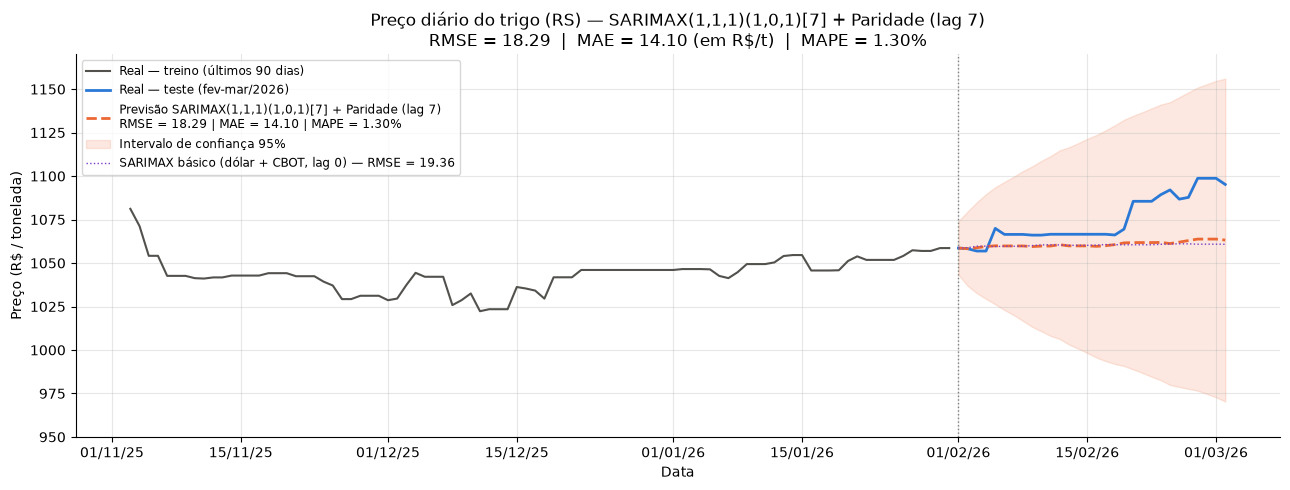

In [16]:
contexto = y_treino.iloc[-90:]   # últimos 90 dias do treino

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(contexto, color="#52514e", lw=1.5, label="Real — treino (últimos 90 dias)")
ax.plot(y_teste,  color="#2a78d6", lw=2,   label="Real — teste (fev-mar/2026)")
ax.plot(y_prev,   color="#eb6834", lw=2, ls="--",
        label=f"Previsão {NOME_FINAL}\nRMSE = {rmse:.2f} | MAE = {mae:.2f} | MAPE = {mape:.2f}%")
ax.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],
                color="#eb6834", alpha=0.15, label="Intervalo de confiança 95%")
if MODELO_FINAL != NOME_BASICO:
    ax.plot(y_prev_basico, color="#7a3cc8", lw=1, ls=":",
            label=f"SARIMAX básico (dólar + CBOT, lag 0) — RMSE = {m_basico['RMSE']:.2f}")
ax.axvline(y_teste.index[0], color="gray", ls=":", lw=1)   # linha do corte treino/teste

ax.set_title(f"Preço diário do trigo (RS) — {NOME_FINAL}\n"
             f"RMSE = {rmse:.2f}  |  MAE = {mae:.2f} (em R$/t)  |  MAPE = {mape:.2f}%")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / tonelada)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(950, 1170)   # mesma escala do sarima_previsao_trigo.png, para comparação visual justa
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/sarimax_previsao_trigo.png", dpi=300)
plt.show()

### 5.2 Exportação das métricas

Mesmo formato do `metricas_sarima_trigo.csv`, com o SARIMAX básico e o aprimorado, para montar a tabela comparativa do trigo.

In [17]:
comparativo.drop(index="SARIMA(1,1,1)(1,0,1)[7]")[["AIC", "BIC", "RMSE", "MAE", "MAPE"]] \
  .reset_index().round(4).to_csv(f"{PASTA_SAIDA}/metricas_sarimax_trigo.csv", index=False)

for arquivo in ["sarimax_previsao_trigo.png", "metricas_sarimax_trigo.csv"]:
    caminho = os.path.join(PASTA_SAIDA, arquivo)
    print(f"{caminho:<40} salvo: {os.path.exists(caminho)}  ({os.path.getsize(caminho):,} bytes)")

pd.read_csv(f"{PASTA_SAIDA}/metricas_sarimax_trigo.csv")

outputs\sarimax_previsao_trigo.png       salvo: True  (270,883 bytes)
outputs\metricas_sarimax_trigo.csv       salvo: True  (241 bytes)


,modelo,AIC,BIC,RMSE,MAE,MAPE
0,"SARIMAX(1,1,1)(1,0,1)[7] + dólar + CBOT (básico, lag 0)",45830.9507,45878.4868,19.3556,14.7316,1.3567
1,"SARIMAX(1,1,1)(1,0,1)[7] + Paridade (lag 7) (aprimorado)",45777.3171,45818.0624,18.2936,14.1032,1.2992


## Conclusão

**Seleção (AIC no treino, mesma amostra para todos os candidatos):**

- **Defasagem é o que importa.** No mesmo dia ($k = 0$), câmbio e CBOT não acrescentam nada ao SARIMA (Δ AIC ≈ 0 e coeficientes com sinal
  negativo, contrário ao esperado). Com defasagem, o sinal fica **positivo e significativo**, como prevê a paridade de importação, e o AIC cai:
  o efeito é máximo em **7 dias** e vai se dissipando em 14 e 21 dias, até desaparecer em 30 dias (p ≈ 0,3 a 0,5). A correlação defasada da
  seção 2.2 mostra o mesmo padrão: pico em 7 dias (r ≈ 0,09 para a paridade) contra r ≈ 0 no mesmo dia. É a evidência empírica do
  ***transmission lag***: o mercado gaúcho leva cerca de uma semana para incorporar os movimentos de Chicago e do câmbio.
- **Paridade única > variáveis separadas.** Com a mesma defasagem, o índice `CBOT × dólar` tem AIC menor que o par dólar + CBOT
  (45.777 contra 45.799 em 7 dias), com um parâmetro a menos. O mercado reage ao **custo de importação em reais**, não a cada componente isoladamente.
- **Modelo final:** SARIMAX(1,1,1)(1,0,1)[7] + `paridade_lag_7`, com **Δ AIC = −53,2** em relação ao SARIMA (evidência muito forte; o limiar usual é 2).
  Coeficiente = 0,041 (p < 0,001): cada R\$ 1/t de variação na paridade se reflete em ≈ R\$ 0,04/t na variação do preço do trigo
  gaúcho uma semana depois. Ao absorver essa informação, os termos ARMA não sazonais perdem força ($\phi_1$ de −0,85 para −0,38;
  $\theta_1$ de 0,83 para 0,34), reduzindo a sobreparametrização apontada no SARIMA.
- **Precipitação = ruído.** Nenhuma das quatro versões (no dia, acumulada em 7, 15 e 30 dias) é significativa (p de 0,32 a 0,98) e todas
  **pioram** o AIC (+0,8 a +2,0). Assim como no arroz, a chuva de curto prazo não explica a variação diária do preço; o efeito do clima,
  se existir, aparece na safra como um todo, não no dia a dia do mercado.

**Desempenho no teste (01/02 a 02/03/2026):**

| Modelo | AIC | RMSE | MAE | MAPE |
|---|---|---|---|---|
| SARIMA(1,1,1)(1,0,1)[7] | 45.830,5 | 19,29 | 14,68 | 1,35% |
| SARIMAX básico (dólar + CBOT, lag 0) | 45.831,0 | 19,36 | 14,73 | 1,36% |
| **SARIMAX aprimorado (paridade, lag 7)** | **45.777,3** | **18,29** | **14,10** | **1,30%** |

- O modelo aprimorado reduz o RMSE em **≈ 5%** em relação ao SARIMA. O critério de seleção concordou com o teste: na tabela 4.2, os candidatos
  com melhor AIC também estão entre os de menor erro, e os que pioram o AIC pioram o erro.
- **O ganho é modesto e a projeção continua quase plana.** O modelo sobe de R\$ 1.058,6 para ≈ R\$ 1.063/t, enquanto o preço real sobe
  ≈ R\$ 37/t no fim de fevereiro. A paridade de 7 dias antes só subiu forte a partir de 19/02, e o coeficiente diário de 0,04 transmite
  apenas uma fração do movimento — a maior parte da alta do teste continua não explicada.

**Limitações:**

- Com defasagem de 7 dias, só os **7 primeiros dias** do teste usam paridade já conhecida em 31/01/2026; do 8º dia em diante, o modelo usa a
  paridade **observada** (como o SARIMAX do arroz usa a chuva observada). Numa previsão operacional de 30 dias, a paridade também teria de ser prevista.
- A grade de defasagens (0, 7, 14, 21 e 30 dias) é grossa: o ótimo pode estar entre 1 e 13 dias. Resíduos continuam com
  heterocedasticidade (H ≈ 4,5) e caudas pesadas (curtose ≈ 25), e a CBOT do Yahoo Finance (`ZW=F`) tem saltos nas trocas de vencimento.

**Próximos passos:** refinar a defasagem (de 1 a 14 dias) e testar **várias defasagens da paridade ao mesmo tempo** (por exemplo, 7 e 14 dias),
sempre escolhendo pelo AIC no treino; e levar a `paridade_lag_7` para a LSTM do trigo como variável de entrada.